In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
mlb_raw = pd.read_csv('mlb_23_25_fangraphs.csv')
mlb_total = pd.read_csv('fangraphs_23_25_total.csv')

In [3]:
mlb_raw.columns

Index(['Name', 'Team', 'G', 'PA', 'AVG', 'BB%', 'K%', 'OBP', 'SLG', 'OPS',
       'ISO', 'BABIP', 'LD%', 'GB%', 'FB%', 'wOBA', 'Barrel%', 'maxEV',
       'HardHit%', 'xBA', 'xSLG', 'xwOBA', 'EV90', 'Events', 'NameASCII',
       'PlayerId', 'MLBAMID'],
      dtype='object')

In [4]:
mlb_total.columns

Index(['Name', 'Team', 'PA', 'AVG', 'BB%', 'K%', 'OBP', 'SLG', 'OPS', 'ISO',
       'BABIP', 'GB/FB', 'LD%', 'GB%', 'FB%', 'IFFB%', 'wRC+', 'O-Swing% (sc)',
       'Z-Swing% (sc)', 'Swing% (sc)', 'O-Contact% (sc)', 'Z-Contact% (sc)',
       'Contact% (sc)', 'Soft%', 'EV', 'LA', 'Barrel%', 'maxEV', 'HardHit%',
       'xwOBA', 'EV90', 'NameASCII', 'PlayerId', 'MLBAMID'],
      dtype='object')

In [6]:
min_bbe = 100
min_pa = 1000

In [20]:
mlb = mlb_raw[mlb_raw['Events'] >= min_bbe]

In [7]:
mlb_t = mlb_total[mlb_total['PA'] >= min_pa]

In [33]:
corr = mlb[['AVG', 'BB%', 'K%', 'OBP', 'SLG', 'OPS',
       'ISO', 'BABIP', 'LD%', 'GB%', 'FB%', 'wOBA', 'Barrel%', 'maxEV',
       'HardHit%', 'xBA', 'xSLG', 'xwOBA', 'EV90']].corr(method='spearman')

NameError: name 'mlb' is not defined

In [34]:
corr = mlb_t[['AVG', 'BB%', 'K%', 'OBP', 'SLG', 'OPS', 'ISO',
       'BABIP', 'GB/FB', 'LD%', 'GB%', 'FB%', 'IFFB%', 'wRC+', 'O-Swing% (sc)',
       'Z-Swing% (sc)', 'Swing% (sc)', 'O-Contact% (sc)', 'Z-Contact% (sc)',
       'Contact% (sc)', 'Soft%', 'EV', 'LA', 'Barrel%', 'maxEV', 'HardHit%',
       'xwOBA', 'EV90']].corr(method='spearman')

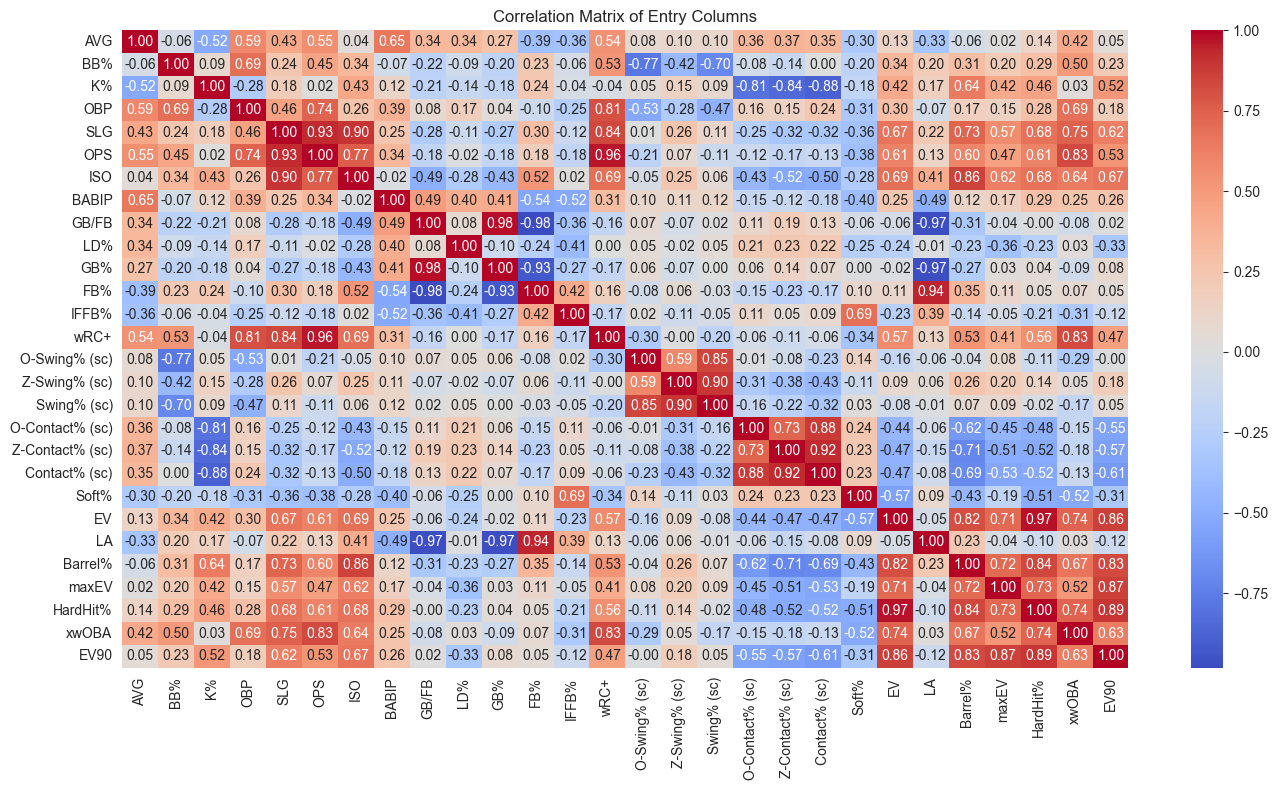

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix of Entry Columns")
plt.tight_layout()
plt.show()

In [15]:
import matplotlib.pyplot as plt

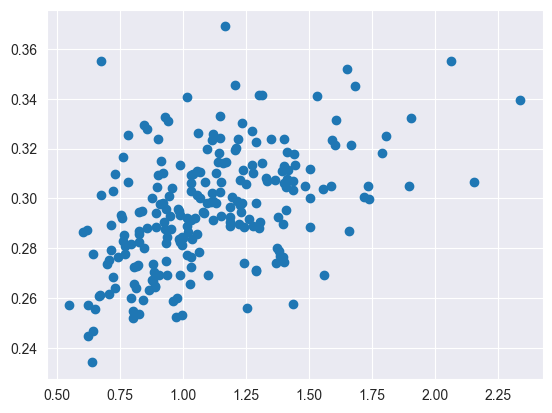

In [16]:
plt.scatter(mlb_t['GB/FB'], mlb_t['BABIP'])

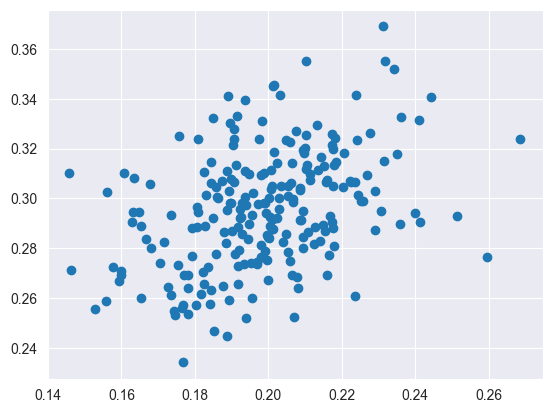

In [17]:
plt.scatter(mlb_t['LD%'], mlb_t['BABIP'])

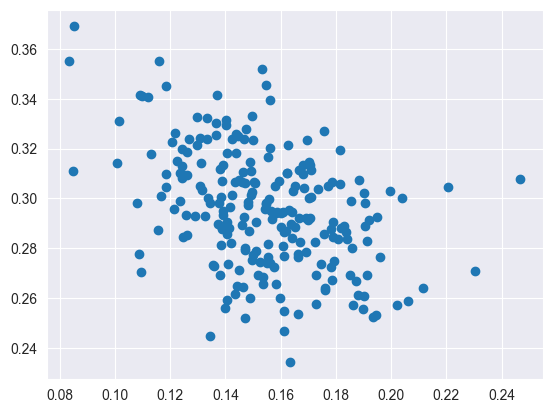

In [18]:
plt.scatter(mlb_t['Soft%'], mlb_t['BABIP'])

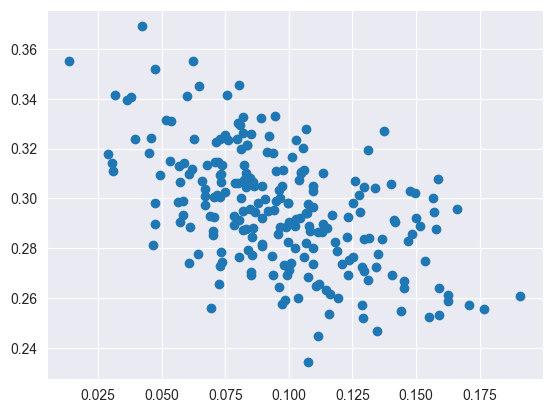

In [19]:
plt.scatter(mlb_t['IFFB%'], mlb_t['BABIP'])

In [20]:
df = mlb_t.copy()

In [40]:
import statsmodels.api as sm
import numpy as np

# 1. Create the dummy variable: 1 if GB/FB > 1.5, else 0
# We use .astype(int) to make it compatible with the regression
df['High_GB_FB'] = (df['GB/FB'] > 1.5).astype(int)

# 2. Define features (including the new dummy)
features = ['FB%', 'LD%', 'Barrel%']
X = df[features]
y = df['BABIP']

# 3. Add constant and split
X = sm.add_constant(X)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Fit the model
model_with_dummy = sm.OLS(y_train, X_train).fit()

# 5. Review Results
print(model_with_dummy.summary())

                            OLS Regression Results                            
Dep. Variable:                  BABIP   R-squared:                       0.559
Model:                            OLS   Adj. R-squared:                  0.552
Method:                 Least Squares   F-statistic:                     75.66
Date:                Mon, 23 Feb 2026   Prob (F-statistic):           1.19e-31
Time:                        22:44:43   Log-Likelihood:                 496.86
No. Observations:                 183   AIC:                            -985.7
Df Residuals:                     179   BIC:                            -972.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2909      0.017     16.765      0.0

<Axes: xlabel='Barrel%', ylabel='Count'>

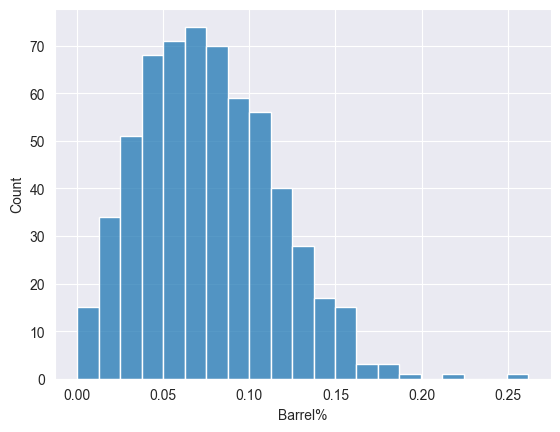

In [23]:
sns.histplot(mlb['Barrel%'])

In [186]:
import statsmodels.api as sm

X = mlb[['Barrel%', 'FB%', 'EV90', 'LD%']].copy()
y = mlb['BABIP']

In [187]:
from sklearn.preprocessing import StandardScaler
X_scaled = StandardScaler().fit_transform(X)

In [188]:
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)


In [189]:


X_scaled = sm.add_constant(X_scaled)
model = sm.OLS(y, X_scaled)
results = model.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                  BABIP   R-squared:                       0.567
Model:                            OLS   Adj. R-squared:                  0.557
Method:                 Least Squares   F-statistic:                     53.42
Date:                Fri, 16 Jan 2026   Prob (F-statistic):           1.06e-28
Time:                        22:58:33   Log-Likelihood:                 473.71
No. Observations:                 168   AIC:                            -937.4
Df Residuals:                     163   BIC:                            -921.8
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2963      0.001    262.238      0.0

In [190]:
import numpy as np
import itertools
import pandas as pd

# 1. Base names from scaled DataFrame
base_names = list(X_scaled_df.columns)

# 2. Convert to NumPy
X_np = X_scaled_df.to_numpy()

n_samples, n_features = X_np.shape

interaction_terms = []
interaction_names = []

# 3. Generate interaction columns + names
for i, j in itertools.combinations(range(n_features), 2):
    inter = (X_np[:, i] * X_np[:, j]).reshape(-1, 1)
    interaction_terms.append(inter)
    interaction_names.append(f"{base_names[i]}_x_{base_names[j]}")

# 4. Combine original + interactions safely
if interaction_terms:
    X_inter_np = np.hstack([X_np] + interaction_terms)
else:
    X_inter_np = X_np.copy()

# 5. Build full feature name list
feature_names = base_names + interaction_names

# 6. Rebuild DataFrame
X_inter = pd.DataFrame(
    X_inter_np,
    columns=feature_names,
    index=X_scaled_df.index
)


In [191]:
def bic_for_model(X, y):
    X_const = sm.add_constant(X, has_constant='add')
    model = sm.OLS(y, X_const).fit()
    return model.bic, model

def stepwise_bic(X, y, feature_names, verbose=True):
    """
    X: numpy ndarray, shape (n_samples, n_features)
    y: array-like, shape (n_samples,)
    feature_names: list of feature names, length n_features
    """
    n_features = X.shape[1]
    remaining = list(range(n_features))
    selected = []
    current_bic = np.inf
    current_model = None

    improved = True
    while improved:
        improved = False
        best_candidate = None
        best_bic = current_bic
        best_model = current_model

        # ----- Forward step -----
        for j in remaining:
            candidate_idx = selected + [j]
            X_candidate = X[:, candidate_idx]
            bic, model = bic_for_model(X_candidate, y)

            if bic < best_bic - 1e-6:  # small tolerance
                best_bic = bic
                best_candidate = ('add', j, candidate_idx, model)

        # ----- Backward step -----
        if len(selected) > 1:
            for j in selected:
                candidate_idx = [k for k in selected if k != j]
                X_candidate = X[:, candidate_idx]
                bic, model = bic_for_model(X_candidate, y)

                if bic < best_bic - 1e-6:
                    best_bic = bic
                    best_candidate = ('remove', j, candidate_idx, model)

        # ----- Apply best move -----
        if best_candidate is not None:
            move, j, new_selected, model = best_candidate
            selected = new_selected
            remaining = [k for k in range(n_features) if k not in selected]
            current_bic = best_bic
            current_model = model
            improved = True

            if verbose:
                if move == 'add':
                    print(f"ADD {feature_names[j]:<30} BIC = {current_bic:.3f}")
                else:
                    print(f"REMOVE {feature_names[j]:<27} BIC = {current_bic:.3f}")

    selected_names = [feature_names[i] for i in selected]
    return selected, selected_names, current_model


In [194]:
# X_inter: ndarray (original + interactions, no intercept)
# feature_names: list of names for X_inter columns
# y: hpa['avg'].values or similar

selected_idx, selected_names, final_model = stepwise_bic(
    X_inter.values,          # <-- NumPy array
    y,
    list(X_inter.columns),   # <-- list of names
    verbose=True
)


print("\nSelected features:")
for name in selected_names:
    print("  ", name)

print("\nFinal model summary:")
print(final_model.summary())


ADD FB%                            BIC = -850.615
ADD Barrel%                        BIC = -900.595
ADD LD%                            BIC = -922.617
ADD Barrel%_x_LD%                  BIC = -928.488

Selected features:
   FB%
   Barrel%
   LD%
   Barrel%_x_LD%

Final model summary:
                            OLS Regression Results                            
Dep. Variable:                  BABIP   R-squared:                       0.584
Model:                            OLS   Adj. R-squared:                  0.574
Method:                 Least Squares   F-statistic:                     57.25
Date:                Fri, 16 Jan 2026   Prob (F-statistic):           4.23e-30
Time:                        23:00:06   Log-Likelihood:                 477.05
No. Observations:                 168   AIC:                            -944.1
Df Residuals:                     163   BIC:                            -928.5
Df Model:                           4                                         
Covar

In [193]:
print("X_inter shape:", X_inter.shape)
print("len(feature_names):", len(feature_names))


X_inter shape: (168, 10)
len(feature_names): 10
